# ЛР2 - SVD

# Singular Value Decomposition (SVD)

**Разложение по сингулярным значениям** (SVD) - это рабочая лошадка в приложениях проекции наименьших квадратов, которая
составляют основу для многих статистических методов и методов машинного обучения.

После определения SVD мы опишем, как он подключается к

- **четыре фундаментальных пространства** линейной алгебры
- недоопределенные и переопределенные **регрессии наименьших квадратов**
- **Анализ главных компонентов** (PCA)


Как и анализ главных компонентов (PCA), SVD можно рассматривать как процедуру сокращения данных, которая представляет существенные закономерности путем проецирования данных на ограниченный набор факторов.


## Настройка

Пусть $X$ — матрица $m\times n$ ранга $p$.

Обязательно $p\leq\min(m,n)$.

На протяжении большей части этой лекции мы будем думать о $X$ как о матрице **данных**, в которой

- в каждом столбце указано **индивидуальное** – период времени или человек, в зависимости от приложения.
- каждая строка представляет собой **случайную величину**, описывающую атрибут периода времени или человека, в зависимости от приложения


Нас будут интересовать две ситуации

- **1** случай (short and fat) в котором $ m << n $, так что столбцов (отдельных лиц) намного больше, чем строк (атрибутов).
- **2** случай (tall and skinny), в котором $m >> n$, так что строк (атрибутов) гораздо больше, чем столбцов (отдельных лиц).


В обеих ситуациях мы применим **разложение по сингулярным значениям** $X$.

В случае $ m < < n $, когда особей $ n $ гораздо больше, чем атрибутов $ m $, мы можем вычислить моменты выборки совместного распределения, взяв средние значения по наблюдениям функций наблюдений.

В этом случае $ m < < n $ мы будем искать **шаблоны**, используя **разложение по сингулярным значениям** для выполнения **анализа главных компонентов** (PCA).

В случае $ m >> n $, когда атрибутов $ m $ намного больше, чем индивидов $ n $, и когда мы находимся в настройке временного ряда, в которой $ n $ равно количеству периодов времени, охватываемых набором данных $ X $, мы поступим другим способом.

Мы снова будем использовать **разложение по сингулярным значениям**, но теперь для построения **разложения по динамическим режимам** (DMD).

## Singular Value Decomposition


**Разложение по сингулярным значениям** $ m \times n $ матрицы $ X $ ранга $ p \leq \min(m,n) $ есть

<a id='equation-eq-svd101'></a>
$$
X  = U \Sigma V^\top \tag{5.1}
$$

where

$$
\begin{aligned}
UU^\top  &  = I  &  \quad U^\top  U = I \cr
VV^\top  & = I & \quad V^\top  V = I
\end{aligned}
$$

and

-$U$ — $m\times m$ ортогональная матрица **левых сингулярных векторов** матрицы $X$
- Столбцы $U$ являются собственными векторами $X X^\top$
- $V$ — это $n\times n$ ортогональная матрица **правых сингулярных векторов** матрицы $X$
- Столбцы $V$ являются собственными векторами $X^\top X$
- $\Sigma$ — $m\times n$-матрица, в которой первые $p$ места на ее главной диагонали являются положительными числами $\sigma_1, \sigma_2, \ldots, \sigma_p$, называемыми **сингулярными значениями**; все остальные записи $\Sigma$ равны нулю
- Сингулярные значения $p$ являются положительными квадратными корнями из собственных значений матрицы $m\times m$ $X X^\top$, а также матрицы $n\times n$ $X^\top X$
- Мы принимаем соглашение, согласно которому, когда $ U $ является комплексной матрицей, $ U^\top $ обозначает **сопряженное транспонирование** или **эрмитово транспонирование** $ U $, что означает, что
$ U_{ij}^\top$ — комплексно-сопряженный элемент $U_{ji}$.
- Аналогично, когда $V$ является комплексной матрицей, $V^\top$ обозначает **сопряженное транспонирование** или **эрмитово транспонирование** $V $.


Матрицы $U,\Sigma,V$ влекут за собой линейные преобразования, изменяющие форму векторов следующими способами:

- умножение векторов на унитарные матрицы $U$ и $V$ **поворачивает** их, но оставляет **углы между векторами** и **длины векторов** неизменными.
- умножение векторов на диагональную матрицу $\Sigma$ оставляет **углы между векторами** неизменными, но **перемасштабирует** векторы.


Таким образом, представление [(5.1)](#equation-eq-svd101) утверждает, что умножение $ n \times 1$ вектора $y$ на $m \times n$ матрицу $X$
сводится к последовательному выполнению следующих трёх умножений $y$:

- **вращение** $ y $ путем вычисления $ V^\top y $
- **масштабирование** $ V^\top y $ путем умножения на $ \Sigma $
- **вращение** $ \Sigma V^\top y $ путем умножения на $ U $


Такая структура матрицы $m\times n$ $X$ открывает двери для построения систем
**кодеров** и **декодеров** данных.

Таким образом,

- $V^\top y$ — кодировщик
- $\Sigma$ — оператор, применяемый к закодированным данным
— $U$ — декодер, который будет применяться к выходу применения оператора $\Sigma$ к закодированным данным


Мы применим этот круг идей позже в этой лекции, когда будем изучать декомпозицию по динамическому режиму.


То, что мы описали выше, называется **полной** СВД.

В **полном** SVD формы $U$, $\Sigma$ и $V$ имеют вид $\left(m, m\right)$, $\left(m, n\right)$, $\left(n, n\right)$ соответственно.

Позже мы также опишем **экономную** или **уменьшенную** СВД.

Прежде чем мы приступим к изучению **уменьшенного** СВД, скажем немного больше о свойствах **полного** СВД.

## Четыре фундаментальных подпространства

Пусть $ {\mathcal C} $ обозначает пространство столбцов, $ {\mathcal N} $ обозначает нулевое пространство и $ {\mathcal R} $ обозначает пространство строк.

Начнем с напоминания о четырех фундаментальных подпространствах $m\times n$
матрица $X$ ранга $p$.

— **Пространство столбцов** $X$, обозначаемое ${\mathcal C}(X)$, представляет собой диапазон столбцов $X$, т. е. всех векторов $y$, которые можно записать как линейные комбинации столбцов $X$. Его размерность $p$.
- **Нулевое пространство** $ X $, обозначаемое $ {\mathcal N}(X) $, состоит из всех векторов $ y $, удовлетворяющих условиям
$Ху=0$. Его размерность $n-p$.
- **Пространство строк** $ X $, обозначаемое $ {\mathcal R}(X) $, является пространством столбцов $ X^\top $. Он состоит из всех
векторы $z$, которые можно записать как линейные комбинации строк $X$. Его размерность $p$.
- **Левое нулевое пространство** $ X $, обозначаемое $ {\mathcal N}(X^\top ) $, состоит из всех векторов $ z $ таких, что
$ X^\top z =0 $. Его размерность $m-p$.

Для полной СВД матрицы $X$ матрица $U$ левых сингулярных векторов и матрица $V$ правых сингулярных векторов содержат ортогональные базисы для всех четырёх подпространств.

Они образуют две пары ортогональных подпространств, что мы сейчас опишем.

Let $ u_i, i = 1, \ldots, m $ be the $ m $ column vectors of $ U $ and let
$ v_i, i = 1, \ldots, n $ be the $ n $ column vectors of $ V $.

Давайте запишем полный SVD X как

<a id='equation-eq-fullsvdpartition'></a>
$$
X = \begin{bmatrix} U_L & U_R \end{bmatrix} \begin{bmatrix} \Sigma_p & 0 \cr 0 & 0 \end{bmatrix}
     \begin{bmatrix} V_L & V_R \end{bmatrix}^\top \tag{5.2}
$$
где $\Sigma_p$ — диагональная матрица $p\times p$ с сингулярными значениями $p$ на диагонали и
$$
\begin{aligned}
U_L & = \begin{bmatrix}u_1 & \cdots  & u_p \end{bmatrix},  \quad U_R  = \begin{bmatrix}u_{p+1} & \cdots u_m \end{bmatrix}  \cr
V_L & = \begin{bmatrix}v_1 & \cdots  & v_p \end{bmatrix} , \quad U_R  = \begin{bmatrix}v_{p+1} & \cdots u_n \end{bmatrix}
\end{aligned}
$$

Представление [(5.2)](#equation-eq-fullsvdpartition) подразумевает, что

$$
X \begin{bmatrix} V_L & V_R \end{bmatrix} = \begin{bmatrix} U_L & U_R \end{bmatrix} \begin{bmatrix} \Sigma_p & 0 \cr 0 & 0 \end{bmatrix}
$$

или


<a id='equation-eq-xfour1a'></a>
$$
\begin{aligned}
X V_L & = U_L \Sigma_p \cr
X V_R & = 0
\end{aligned} \tag{5.3}
$$

или


<a id='equation-eq-orthoortho1'></a>
$$
\begin{aligned}
X v_i & = \sigma_i u_i , \quad i = 1, \ldots, p \cr
X v_i & = 0 ,  \quad i = p+1, \ldots, n
\end{aligned} \tag{5.4}
$$

Equations [(5.4)](#equation-eq-orthoortho1) tell how the transformation $ X $ maps a pair of orthonormal  vectors $ v_i, v_j $ for $ i $ and $ j $ both less than or equal to the rank $ p $ of $ X $ into a pair of orthonormal vectors $ u_i, u_j $.

Equations [(5.3)](#equation-eq-xfour1a) assert that

$$
\begin{aligned}
{\mathcal C}(X) & = {\mathcal C}(U_L) \cr
{\mathcal N}(X) & = {\mathcal C} (V_R)
\end{aligned}
$$

Taking transposes on both sides of representation [(5.2)](#equation-eq-fullsvdpartition) implies

$$
X^\top  \begin{bmatrix} U_L & U_R \end{bmatrix} = \begin{bmatrix} V_L & V_R \end{bmatrix} \begin{bmatrix} \Sigma_p & 0 \cr 0 & 0 \end{bmatrix}
$$

или


<a id='equation-eq-xfour1b'></a>
$$
\begin{aligned}
X^\top  U_L & = V_L \Sigma_p \cr
X^\top  U_R & = 0
\end{aligned} \tag{5.5}
$$

или


<a id='equation-eq-orthoortho2'></a>
$$
\begin{aligned}
X^\top  u_i & = \sigma_i v_i, \quad i=1, \ldots, p \cr
X^\top  u_i & = 0 \quad i= p+1, \ldots, m
\end{aligned} \tag{5.6}
$$

Обратите внимание, как уравнения [(5.6)](#equation-eq-orthoortho2) утверждают, что преобразование $X^\top$ отображает пару различных ортонормированных векторов $u_i, u_j$ для $i$ и $j$, которые меньше или равны рангу $p$ $X$, в пару различных ортонормированных векторов $v_i, v_j$.

Equations [(5.5)](#equation-eq-xfour1b) assert that

$$
\begin{aligned}
{\mathcal R}(X) & \equiv  {\mathcal C}(X^\top ) = {\mathcal C} (V_L) \cr
{\mathcal N}(X^\top ) & = {\mathcal C}(U_R)
\end{aligned}
$$
Таким образом, в совокупности системы уравнений [(5.3)](#equation-eq-xfour1a) и [(5.5)](#equation-eq-xfour1b)
опишите четыре фундаментальных подпространства $X$ следующими способами:


<a id='equation-eq-fourspacesvd'></a>
$$
\begin{aligned}
{\mathcal C}(X) & = {\mathcal C}(U_L) \cr
{\mathcal N}(X^\top ) & = {\mathcal C}(U_R) \cr
{\mathcal R}(X) & \equiv  {\mathcal C}(X^\top ) = {\mathcal C} (V_L) \cr
{\mathcal N}(X) & = {\mathcal C} (V_R) \cr

\end{aligned} \tag{5.7}
$$

Поскольку $U$ и $V$ являются ортонормированными матрицами, набор [(5.7)](#equation-eq-fourspacesvd) утверждает, что

— $U_L$ — ортонормированный базис пространства столбцов $X$
- $U_R$ — ортонормированный базис нуль-пространства $X^\top$
- $V_L$ — ортонормированный базис для пространства строк $X$
— $V_R$ — ортонормированный базис нулевого пространства $X$


Мы проверили четыре утверждения в [(5.7)](#equation-eq-fourspacesvd), просто выполнив умножения, требуемые в правой части [(5.2)](#equation-eq-fullsvdpartition), и прочитав их.

Утверждения в [(5.7)](#equation-eq-fourspacesvd) и тот факт, что $U$ и $V$ являются унитарными (т.е. ортонормированными) матрицами, подразумевают
что

- пространство столбцов $X$ ортогонально пустому пространству $X^\top$
- нулевое пространство $X$ ортогонально пространству строк $X$


Иногда эти свойства описываются следующими двумя парами ортогональных дополнительных подпространств:

- $ {\mathcal C}(X) $ is the orthogonal complement of $ {\mathcal N}(X^\top ) $  
- $ {\mathcal R}(X) $ is the orthogonal complement  $ {\mathcal N}(X) $  


Давайте сделаем пример.

In [1]:
import numpy as np
import numpy.linalg as LA
import matplotlib.pyplot as plt

np.random.seed(42)  # воспроизводимость случайных примеров

Having imported these modules, let’s do the example.

**Решение.** `np.linalg.svd` возвращает U, S и сразу Vᵀ. Ранг r = число ненулевых σ.
C(A) = U[:, :r], N(Aᵀ) = U[:, r:], R(A) = VT[:r], N(A) = VT[r:].T

In [2]:
np.set_printoptions(precision=2, suppress=True)

# Define the matrix
A = np.array([[1, 2, 3, 4, 5],
              [2, 3, 4, 5, 6],
              [3, 4, 5, 6, 7],
              [4, 5, 6, 7, 8],
              [5, 6, 7, 8, 9]])

# Вычислите SVD матрицы c помощью np.linalg.svd
U, S, VT = np.linalg.svd(A)          # полное SVD: U (5x5), S (5,), VT = V^T (5x5)

# Вычислить ранг матрицы linalg.matrix_rank
rank = np.linalg.matrix_rank(A)

# Вывести все на печать
print("Сингулярные числа:", S)
print("Ранг матрицы A:", rank)

# Вычислите 4 фундаментальных пространства
col_space = U[:, :rank]              # C(A)    = C(U_L)
left_null_space = U[:, rank:]        # N(A^T)  = C(U_R)
row_space = VT[:rank, :]             # R(A)    = C(V_L), строки V^T
null_space = VT[rank:, :].T          # N(A)    = C(V_R), записываем столбцами

# вывести все на печать
print("U:\n", U)
print("Column space:\n", col_space)
print("Left null space:\n", left_null_space)
print("V.T:\n", VT)
print("Row space:\n", row_space)
print("Right null space:\n", null_space)

Сингулярные числа: [26.86  1.86  0.    0.    0.  ]
Ранг матрицы A: 2
U:
 [[-0.27 -0.73  0.61 -0.17  0.02]
 [-0.35 -0.42 -0.55  0.43  0.46]
 [-0.43 -0.11 -0.28  0.09 -0.85]
 [-0.51  0.19 -0.23 -0.77  0.23]
 [-0.59  0.5   0.45  0.43  0.13]]
Column space:
 [[-0.27 -0.73]
 [-0.35 -0.42]
 [-0.43 -0.11]
 [-0.51  0.19]
 [-0.59  0.5 ]]
Left null space:
 [[ 0.61 -0.17  0.02]
 [-0.55  0.43  0.46]
 [-0.28  0.09 -0.85]
 [-0.23 -0.77  0.23]
 [ 0.45  0.43  0.13]]
V.T:
 [[-0.27 -0.35 -0.43 -0.51 -0.59]
 [ 0.73  0.42  0.11 -0.19 -0.5 ]
 [-0.38  0.49 -0.27  0.59 -0.43]
 [-0.43  0.07  0.83 -0.18 -0.3 ]
 [-0.27  0.67 -0.19 -0.56  0.35]]
Row space:
 [[-0.27 -0.35 -0.43 -0.51 -0.59]
 [ 0.73  0.42  0.11 -0.19 -0.5 ]]
Right null space:
 [[-0.38 -0.43 -0.27]
 [ 0.49  0.07  0.67]
 [-0.27  0.83 -0.19]
 [ 0.59 -0.18 -0.56]
 [-0.43 -0.3   0.35]]


Ранг 2. Проверка подпространств и ортогональности:

In [3]:
print("A @ (базис N(A)) ≈ 0:      ", np.allclose(A @ null_space, 0))
print("A^T @ (базис N(A^T)) ≈ 0:  ", np.allclose(A.T @ left_null_space, 0))
print("C(A) ⟂ N(A^T):             ", np.allclose(col_space.T @ left_null_space, 0))
print("R(A) ⟂ N(A):               ", np.allclose(row_space @ null_space, 0))

# Любой столбец A лежит в C(A): проекция на C(A) возвращает его без изменений
P_col = col_space @ col_space.T
print("Столбцы A лежат в C(A):     ", np.allclose(P_col @ A, A))
# Сумма размерностей: dim C(A) + dim N(A^T) = m, dim R(A) + dim N(A) = n
print("Размерности: C(A) =", col_space.shape[1], ", N(A^T) =", left_null_space.shape[1],
      ", R(A) =", row_space.shape[0], ", N(A) =", null_space.shape[1])

A @ (базис N(A)) ≈ 0:       True
A^T @ (базис N(A^T)) ≈ 0:   True
C(A) ⟂ N(A^T):              True
R(A) ⟂ N(A):                True
Столбцы A лежат в C(A):      True
Размерности: C(A) = 2 , N(A^T) = 3 , R(A) = 2 , N(A) = 3


Все проверки True.

## Теорема Эккарта-Янга

Предположим, что мы хотим построить наилучшее приближение ранга $r$ $m\times n$-матрицы $X$.

Под наилучшей мы понимаем матрицу $X_r$ ранга $r<p$, которая среди всех матриц ранга $r$ минимизирует

$$
|| X - X_r ||
$$

где $ || \cdot || $ обозначает норму матрицы $X$ и где $X_r$ принадлежит пространству всех матриц ранга $r$
размерности $m\times n$.

Три популярные **матричные нормы** $ m \times n$ матрицы $ X $ можно выразить через сингулярные значения $ X $

- **спектральная** или $l^2$ норма $ || X ||_2 = \max_{||y|| \neq 0} \frac{||X y ||}{||y||} = \sigma_1 $
- норма **Фробениуса** $ ||X ||_F = \sqrt{\sigma_1^2 + \cdots + \sigma_p^2} $
- **ядерная** норма $ || X ||_N = \sigma_1 + \cdots + \sigma_p $

Теорема Эккарта-Янга утверждает, что для каждой из этих трех норм матрица $r$ одного и того же ранга является наилучшей и что она равна

<a id='equation-eq-ekart'></a>
$$
\hat X_r = \sigma_1 U_1 V_1^\top  + \sigma_2 U_2 V_2^\top  + \cdots + \sigma_r U_r V_r^\top \tag{5.8}
$$

Это очень мощная теорема, которая гласит, что мы можем взять нашу $m\times n$матрицу $X$, которая не в полном ранге, и лучше всего аппроксимировать ее матрицей $p\times p$ полного ранга через SVD.

Более того, если некоторые из этих $p$ сингулярных значений несут больше информации, чем другие, и если мы хотим иметь наибольшее количество информации с наименьшим количеством данных, мы можем взять $r$ ведущие сингулярные значения, упорядоченные по величине.

Мы расскажем об этом подробнее позже, когда представим анализ главных компонентов.

Вы можете прочитать о теореме Эккарта-Янга и некоторых ее применениях [здесь] (https://en.wikipedia.org/wiki/Low-rank_approximation).

Мы будем использовать эту теорему, когда будем обсуждать анализ главных компонентов (PCA), а также динамическую модовую декомпозицию (DMD).

**Проверка Эккарта–Янга** на картинке 427×640: ошибка должна быть σ_{r+1} и √(Σσᵢ²).

In [4]:
from sklearn.datasets import load_sample_image

img = load_sample_image("china.jpg").mean(axis=2)   # 427 x 640, оттенки серого
U_i, s_i, VT_i = np.linalg.svd(img, full_matrices=False)

def rank_r_approx(U, s, VT, r):
    """Усечённое SVD: сумма первых r слагаемых sigma_i * u_i v_i^T."""
    return (U[:, :r] * s[:r]) @ VT[:r, :]

rng = np.random.default_rng(0)
print(f"{'r':>4} | {'||X-Xr||_2':>11} {'sigma_r+1':>10} | {'||X-Xr||_F':>11} {'sqrt(sum)':>10} | {'случайный ранг r, F':>20}")
for r in [1, 5, 20, 50, 100]:
    Xr = rank_r_approx(U_i, s_i, VT_i, r)
    err2, errF = np.linalg.norm(img - Xr, 2), np.linalg.norm(img - Xr, 'fro')
    # конкурент: проекция на случайное r-мерное подпространство
    Q, _ = np.linalg.qr(rng.normal(size=(img.shape[0], r)))
    errF_rand = np.linalg.norm(img - Q @ (Q.T @ img), 'fro')
    print(f"{r:>4} | {err2:11.2f} {s_i[r]:10.2f} | {errF:11.2f} {np.sqrt((s_i[r:]**2).sum()):10.2f} | {errF_rand:20.2f}")

   r |  ||X-Xr||_2  sigma_r+1 |  ||X-Xr||_F  sqrt(sum) |  случайный ранг r, F
   1 |    15393.34   15393.34 |    25447.25   25447.25 |             87214.64
   5 |     4063.96    4063.96 |    16063.43   16063.43 |             86518.46
  20 |     1874.99    1874.99 |    11896.56   11896.56 |             85704.70
  50 |     1098.33    1098.33 |     8967.58    8967.58 |             82184.97
 100 |      735.85     735.85 |     6416.33    6416.33 |             75121.30


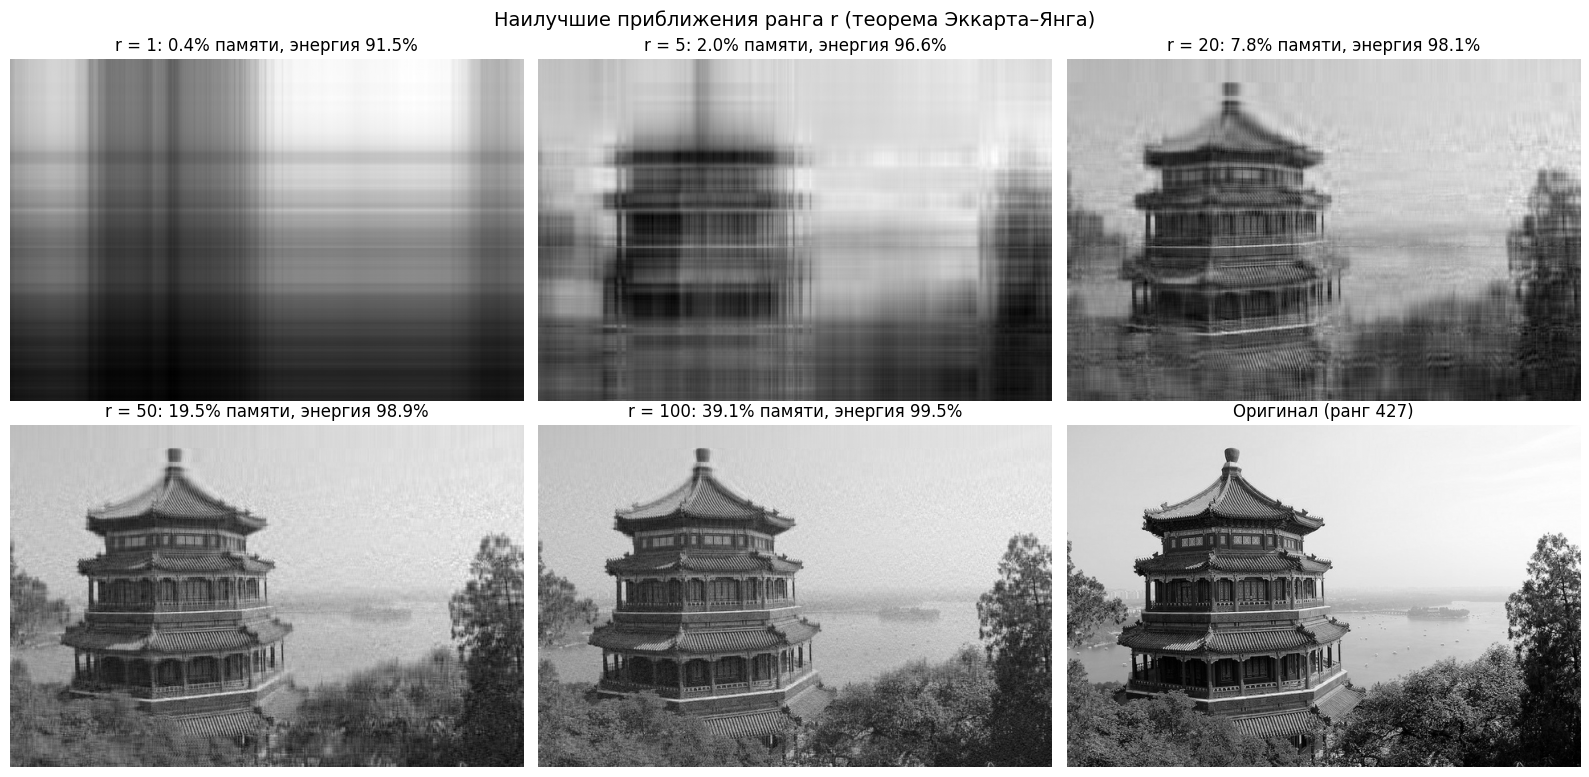

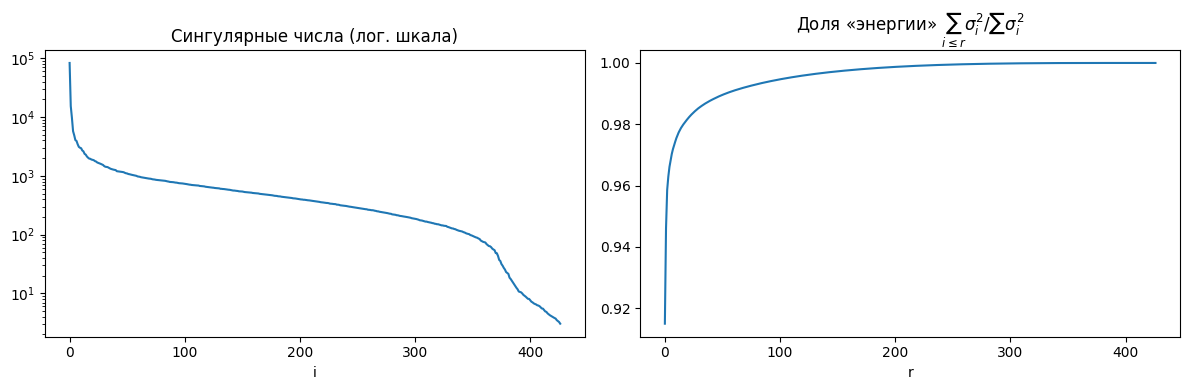

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, r in zip(axes.flat, [1, 5, 20, 50, 100, None]):
    if r is None:
        ax.imshow(img, cmap="gray"); ax.set_title(f"Оригинал (ранг {np.linalg.matrix_rank(img)})")
    else:
        Xr = rank_r_approx(U_i, s_i, VT_i, r)
        stored = r * (img.shape[0] + img.shape[1] + 1) / img.size
        ax.imshow(Xr, cmap="gray")
        ax.set_title(f"r = {r}: {stored:.1%} памяти, энергия {(s_i[:r]**2).sum()/(s_i**2).sum():.1%}")
    ax.axis("off")
plt.suptitle("Наилучшие приближения ранга r (теорема Эккарта–Янга)", fontsize=14)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1); plt.semilogy(s_i); plt.title("Сингулярные числа (лог. шкала)"); plt.xlabel("i")
plt.subplot(1, 2, 2); plt.plot(np.cumsum(s_i**2) / (s_i**2).sum())
plt.title("Доля «энергии» $\\sum_{i\\leq r}\\sigma_i^2/\\sum\\sigma_i^2$"); plt.xlabel("r")
plt.tight_layout(); plt.show()

Формулы совпадают точно; случайная проекция того же ранга в разы хуже. При r = 50 - 19 % памяти почти без потерь.

## Полные и уменьшенные СВД

До сих пор мы описывали свойства **полного** SVD, в котором формы $U$, $\Sigma$ и $V$ имеют вид $\left(m, m\right)$, $\left(m, n\right)$, $\left(n, n\right)$ соответственно.

Существует альтернативное бухгалтерское соглашение, называемое **экономичным** или **уменьшенным** SVD, в котором формы $U, \Sigma$ и $V$ отличаются от того, что они имеют в полном SVD.

Таким образом, обратите внимание: поскольку мы предполагаем, что $X$ имеет ранг $p$, существуют только $p$ ненулевые сингулярные значения, где $p=\textrm{rank}(X)\leq\min\left(m, n\right)$.

**Приведенный** SVD использует этот факт для выражения $U$, $\Sigma$ и $V$ в виде матриц с формами $\left(m, p\right)$, $\left(p, p\right)$, $\left( n, p\right)$.

Про уменьшенную и полную СВД можно прочитать здесь.
[https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html)

Для полной SVD,

$$
\begin{aligned}
UU^\top  &  = I  &  \quad U^\top  U = I \cr
VV^\top  & = I & \quad V^\top  V = I
\end{aligned}
$$

Bоднако не все эти свойства справедливы для **уменьшенной** СВД.

Какие свойства сохраняются, зависит от того, находимся ли мы в случае **высоких-худых** или в случае **низких-толстых**.

- В **высоком-худом** случае, когда $m > > n$, для **уменьшенной** СВД


$$
\begin{aligned}
UU^\top  &  \neq I  &  \quad U^\top  U = I \cr
VV^\top  & = I & \quad V^\top  V = I
\end{aligned}
$$

- **Короткий** случай, когда $ m < < n $, для **уменьшенного** SVD


$$
\begin{aligned}
UU^\top  &  = I  &  \quad U^\top  U = I \cr
VV^\top  & = I & \quad V^\top  V \neq I
\end{aligned}
$$

Когда мы ниже будем изучать динамическую модовую декомпозицию, мы захотим запомнить эти свойства, когда будем использовать сокращенный SVD для вычисления некоторых представлений DMD.

Давайте выполним упражнение, чтобы сравнить **полные** и **уменьшенные** SVD.
Чтобы просмотреть,

- in a **full** SVD  
  - $ U $ is $ m \times m $  
  - $ \Sigma $ is $ m \times n $  
  - $ V $ is $ n \times n $  
- in a **reduced** SVD  
  - $ U $ is $ m \times p $  
  - $ \Sigma $ is $ p\times p $  
  - $ V $ is $ n \times p $  

Сначала рассмотрим случай, когда $m = 5 > n = 2$.

(Это небольшой пример случая **высокий-худой**, который будет интересовать нас, когда мы будем изучать **Динамическое разложение по модам** ниже.)

**Решение:** `full_matrices=True` / `False`.

In [6]:
import numpy as np
X = np.random.rand(5,2)
U, S, V = np.linalg.svd(X, full_matrices=True)            # full SVD
Uhat, Shat, Vhat = np.linalg.svd(X, full_matrices=False)  # economy SVD
print('U, S, V =')
U, S, V

U, S, V =


(array([[-0.56,  0.28, -0.08, -0.67, -0.4 ],
        [-0.49, -0.59, -0.13,  0.44, -0.44],
        [-0.12, -0.1 ,  0.99, -0.03, -0.06],
        [-0.43,  0.69,  0.04,  0.57,  0.1 ],
        [-0.5 , -0.29, -0.05, -0.17,  0.79]]),
 array([1.81, 0.56]),
 array([[-0.5 , -0.86],
        [-0.86,  0.5 ]]))

In [7]:
print('Uhat, Shat, Vhat = ')
Uhat, Shat, Vhat

Uhat, Shat, Vhat = 


(array([[-0.56,  0.28],
        [-0.49, -0.59],
        [-0.12, -0.1 ],
        [-0.43,  0.69],
        [-0.5 , -0.29]]),
 array([1.81, 0.56]),
 array([[-0.5 , -0.86],
        [-0.86,  0.5 ]]))

In [8]:
rr = np.linalg.matrix_rank(X)
print(f'rank of X = {rr}')

rank of X = 2


**Свойства:**

- Где $U$ строится через полный СВД, $U^\top U = I_{m\times m} $ и $ U U^\top = I_{m \times m} $
- Там, где $\hat U$ строится посредством редуцированного СВД, хотя $\hat U^\top\hat U = I_{p\times p}$, бывает, что $\hat U \hat U^\top \neq I_{m \times m} $


Мы проиллюстрируем эти свойства для нашего примера с помощью следующих ячеек кода.

In [9]:
UTU = U.T @ U
UUT = U @ U.T
print('UUT, UTU = ')
UUT, UTU

UUT, UTU = 


(array([[ 1.,  0.,  0., -0., -0.],
        [ 0.,  1.,  0.,  0.,  0.],
        [ 0.,  0.,  1., -0.,  0.],
        [-0.,  0., -0.,  1., -0.],
        [-0.,  0.,  0., -0.,  1.]]),
 array([[ 1.,  0.,  0.,  0.,  0.],
        [ 0.,  1., -0.,  0., -0.],
        [ 0., -0.,  1.,  0.,  0.],
        [ 0.,  0.,  0.,  1.,  0.],
        [ 0., -0.,  0.,  0.,  1.]]))

In [10]:
UhatUhatT = Uhat @ Uhat.T
UhatTUhat = Uhat.T @ Uhat
print('UhatUhatT, UhatTUhat= ')
UhatUhatT, UhatTUhat

UhatUhatT, UhatTUhat= 


(array([[ 0.39,  0.11,  0.04,  0.43,  0.2 ],
        [ 0.11,  0.59,  0.12, -0.2 ,  0.42],
        [ 0.04,  0.12,  0.02, -0.02,  0.09],
        [ 0.43, -0.2 , -0.02,  0.66,  0.01],
        [ 0.2 ,  0.42,  0.09,  0.01,  0.34]]),
 array([[1., 0.],
        [0., 1.]]))

Для экономного SVD Û Ûᵀ ≠ I - это проектор на C(X).

In [11]:
P = Uhat @ Uhat.T
print("Проектор: P^2 = P:", np.allclose(P @ P, P), "| P = P^T:", np.allclose(P, P.T),
      "| след P = ранг =", round(np.trace(P), 6))
print("P X = X (X лежит в своём пространстве столбцов):", np.allclose(P @ X, X))
print("Экономное SVD точно восстанавливает X:", np.allclose(X, Uhat @ np.diag(Shat) @ Vhat))

Проектор: P^2 = P: True | P = P^T: True | след P = ранг = 2.0
P X = X (X лежит в своём пространстве столбцов): True
Экономное SVD точно восстанавливает X: True


**Примечания:**

Ячейки выше иллюстрируют применение опций `full_matrices=True` и `full_matrices=False`.
Использование `full_matrices=False` возвращает уменьшенное разложение по сингулярным значениям.

И **полный**, и **уменьшенный** SVD точно разлагают $ m \times n$ матрицу $ X $

Когда мы будем изучать динамическое разложение по модам ниже, нам будет важно помнить предыдущие свойства полных и уменьшенных SVD в таких случаях с высоким ростом.

Теперь обратимся к короткому делу.

Чтобы проиллюстрировать этот случай, мы установим $ m = 2 < 5 = n $ и вычислим как полные, так и сокращенные SVD.

In [12]:
import numpy as np
X = np.random.rand(2,5)
U, S, V = np.linalg.svd(X, full_matrices=True)              # full SVD
Uhat, Shat, Vhat = np.linalg.svd(X, full_matrices=False)    # economy SVD
print('U, S, V = ')
U, S, V

U, S, V = 


(array([[-0.87, -0.5 ],
        [-0.5 ,  0.87]]),
 array([1.49, 0.41]),
 array([[-0.07, -0.67, -0.66, -0.27, -0.2 ],
        [ 0.36, -0.53,  0.1 ,  0.65,  0.39],
        [-0.62, -0.48,  0.61, -0.09, -0.08],
        [-0.58,  0.21, -0.35,  0.67, -0.22],
        [-0.38,  0.09, -0.23, -0.2 ,  0.87]]))

In [13]:
print('Uhat, Shat, Vhat = ')
Uhat, Shat, Vhat

Uhat, Shat, Vhat = 


(array([[-0.87, -0.5 ],
        [-0.5 ,  0.87]]),
 array([1.49, 0.41]),
 array([[-0.07, -0.67, -0.66, -0.27, -0.2 ],
        [ 0.36, -0.53,  0.1 ,  0.65,  0.39]]))

Let’s verify that our reduced SVD accurately represents $ X $

In [14]:
SShat=np.diag(Shat)
np.allclose(X, Uhat@SShat@Vhat)

True

In [15]:
# В «коротком и толстом» случае роли меняются: теперь неполной является V
V_full, V_hat = V.T, Vhat.T          # V (5x5) и V_hat (5x2)
print("Полное SVD:    V^T V = I:", np.allclose(V_full.T @ V_full, np.eye(5)),
      "| V V^T = I:", np.allclose(V_full @ V_full.T, np.eye(5)))
print("Экономное SVD: V^T V = I:", np.allclose(V_hat.T @ V_hat, np.eye(2)),
      "| V V^T = I:", np.allclose(V_hat @ V_hat.T, np.eye(5)))
print("Экономное SVD: U U^T = I:", np.allclose(Uhat @ Uhat.T, np.eye(2)),
      "| U^T U = I:", np.allclose(Uhat.T @ Uhat, np.eye(2)))

Полное SVD:    V^T V = I: True | V V^T = I: True
Экономное SVD: V^T V = I: True | V V^T = I: False
Экономное SVD: U U^T = I: True | U^T U = I: True


В «коротком» случае наоборот: V̂ V̂ᵀ ≠ I.

## Полярное разложение

**Приведенное** разложение по сингулярным значениям (SVD) $ X $ связано с **полярным разложением** $ X $$

$$
X  = SQ
$$

где

$$
\begin{aligned}
 S & = U\Sigma U^\top  \cr
Q & = U V^\top
\end{aligned}
$$

Здесь

- $ S $ is  an $ m \times m $  **symmetric** matrix  
- $ Q $ is an $ m \times n $  **orthogonal** matrix  


и в нашей reduced SVD

- $ U $ is an $ m \times p $ orthonormal matrix  
- $ \Sigma $ is a $ p \times p $ diagonal matrix  
- $ V $ is an $ n \times p $ orthonormal  

**Проверка полярного разложения**, сверяю со `scipy.linalg.polar`:

In [16]:
from scipy.linalg import polar

X = np.random.rand(3, 5)
Uh, sh, VhT = np.linalg.svd(X, full_matrices=False)
S_pol = Uh @ np.diag(sh) @ Uh.T        # симметричный «растягивающий» множитель (m x m)
Q_pol = Uh @ VhT                       # «поворот» с ортонормированными строками (m x n)

print("X = S Q:                ", np.allclose(X, S_pol @ Q_pol))
print("S симметрична:          ", np.allclose(S_pol, S_pol.T))
print("Собств. числа S >= 0:   ", np.linalg.eigvalsh(S_pol).round(4))
print("Q Q^T = I:              ", np.allclose(Q_pol @ Q_pol.T, np.eye(3)))

Q_sp, S_sp = polar(X, side='left')     # scipy: X = S_sp @ Q_sp
print("Совпадает со scipy.linalg.polar:", np.allclose(S_sp, S_pol) and np.allclose(Q_sp, Q_pol))

X = S Q:                 True
S симметрична:           True
Собств. числа S >= 0:    [0.22 0.72 1.94]
Q Q^T = I:               True
Совпадает со scipy.linalg.polar: True


## Приложение: анализ главных компонентов (PCA)

Начнем со случая, когда $n>>m$, так что особей $n$ у нас гораздо больше, чем атрибутов $m$.

Матрица $ X $ является **короткой и толстой** в случае $ n >> m $, в отличие от случая **высокой и тощей** с $ m >> n $, который будет обсуждаться позже.

Мы рассматриваем $X$ как матрицу $m\times n$ **данных**:

$$
X = \begin{bmatrix} X_1 \mid X_2 \mid \cdots \mid X_n\end{bmatrix}
$$

где для $j = 1, \ldots, n$ вектор-столбец $X_j = \begin{bmatrix}x_{1j}\\x_{2j}\\\vdots\\x_{mj}\end{bmatrix}$ является вектором наблюдений над переменными $ \begin{bmatrix}X_1\\X_2\\\vdots\\X_m\end{bmatrix}$.

В настройке **временных рядов** мы могли бы рассматривать столбцы $j$ как индексирующие различные **моменты**, в которые наблюдаются случайные переменные, а строки индексируют разные случайные величины.

В настройке **перекрестного** мы могли бы рассматривать столбцы $ j $ как индексирующие различные **индивиды**, для которых наблюдаются случайные величины, в то время как строки индексируют различные **атрибуты**.

Как мы видели ранее, SVD — это способ разложить матрицу на полезные компоненты, точно так же, как полярное разложение, собственное разложение и многие другие.

PCA, с другой стороны, представляет собой метод, основанный на SVD для анализа данных. Цель состоит в том, чтобы применить определенные шаги, чтобы помочь лучше визуализировать закономерности в данных, используя статистические инструменты для выявления наиболее важных закономерностей в данных.

**Шаг 1. Стандартизируйте данные:**

Поскольку наша матрица данных может содержать переменные разных единиц и масштабов, сначала нам необходимо стандартизировать данные.

Сначала вычисляя среднее значение каждой строки $X$.

$$
\bar{X_i}= \frac{1}{n} \sum_{j = 1}^{n} x_{ij}
$$

Затем мы создаем среднюю матрицу из этих средств:

$$
\bar{X} = \begin{bmatrix} \bar{X_1} \\ \bar{X_2} \\ \ldots \\ \bar{X_m}\end{bmatrix}\begin{bmatrix}1 \mid 1 \mid \cdots \mid 1 \end{bmatrix}
$$

И вычтите из исходной матрицы, чтобы создать среднецентрированную матрицу:

$$
B = X - \bar{X}
$$

**Шаг 2. Вычислите ковариационную матрицу:**

Затем, поскольку мы хотим извлечь связи между переменными, а не только их величину, другими словами, мы хотим знать, как они могут объяснить друг друга, мы вычисляем ковариационную матрицу $B$.

$$
C = \frac{1}{n} BB^{\top}
$$

**Шаг 3. Разложите ковариационную матрицу и расположите сингулярные значения:**

Поскольку матрица $C$ положительно определена, мы можем разложить ее по собственным значениям, найти ее собственные значения и переставить матрицы собственных значений и собственных векторов в порядке убывания.

Собственное разложение $C$ можно найти, разложив вместо него $B$. Так как $B$ не является квадратной матрицей, то получаем SVD $B$:

$$
\begin{align}
B B^\top &= U \Sigma V^\top (U \Sigma V^{\top})^{\top}\\
&= U \Sigma V^\top V \Sigma^\top U^\top\\
&= U \Sigma \Sigma^\top U^\top
\end{align}
$$

$$
C = \frac{1}{n} U \Sigma \Sigma^\top U^\top
$$

Затем мы можем переставить столбцы в матрицах $U$ и $\Sigma$ так, чтобы сингулярные значения располагались в порядке убывания.

**Шаг 4. Выберите единичные значения и (необязательно) обрежьте остальные:**

Теперь мы можем решить, сколько сингулярных значений выбрать, исходя из того, какую дисперсию вы хотите сохранить. (например, сохранение 95% общей дисперсии).

Мы можем получить процент, рассчитав дисперсию, содержащуюся в ведущих факторах $r$, разделенную на общую дисперсию:

$$
\frac{\sum_{i = 1}^{r} \sigma^2_{i}}{\sum_{i = 1}^{p} \sigma^2_{i}}
$$

**Шаг 5. Создайте матрицу оценок:**

$$
\begin{align}
Т&= БВ \cr
&= U\Sigma V^\top V \cr
&= U\Sigma
\end{align}
$$

## Отношения PCA и SVD
Чтобы связать SVD с PCA набора данных $X$, сначала постройте SVD матрицы данных $X$:

Предположим, что выборочные средние всех переменных равны нулю, поэтому нам не нужно стандартизировать нашу матрицу.


<a id='equation-eq-pca1'></a>
$$
X = U \Sigma V^\top  = \sigma_1 U_1 V_1^\top  + \sigma_2 U_2 V_2^\top  + \cdots + \sigma_p U_p V_p^\top \tag{5.9}
$$

где

$$
U=\begin{bmatrix}U_1|U_2|\ldots|U_m\end{bmatrix}
$$

$$
V^\top  = \begin{bmatrix}V_1^\top \\V_2^\top \\\ldots\\V_n^\top \end{bmatrix}
$$

В уравнении [(5.9)](#equation-eq-pca1) каждая из $m\times n$ матриц $U_{j}V_{j}^\top$ очевидно
ранга $1$.

Таким образом, мы имеем


<a id='equation-eq-pca2'></a>
$$
X = \sigma_1 \begin{bmatrix}U_{11}V_{1}^\top \\U_{21}V_{1}^\top \\\cdots\\U_{m1}V_{1}^\top \\\end{bmatrix} + \sigma_2\begin{bmatrix}U_{12}V_{2}^\top \\U_{22}V_{2}^\top \\\cdots\\U_{m2}V_{2}^\top \\\end{bmatrix}+\ldots + \sigma_p\begin{bmatrix}U_{1p}V_{p}^\top \\U_{2p}V_{p}^\top \\\cdots\\U_{mp}V_{p}^\top \\\end{bmatrix} \tag{5.10}
$$

Вот как мы будем интерпретировать объекты в матричном уравнении [(5.10)](#equation-eq-pca2) в
контекст временного ряда:

- $ \textrm{for each} \   k=1, \ldots, n $, the object $ \lbrace V_{kj} \rbrace_{j=1}^n $ is a time series   for the $ k $th **principal component**  
- $ U_j = \begin{bmatrix}U_{1k}\\U_{2k}\\\ldots\\U_{mk}\end{bmatrix} \  k=1, \ldots, m $
— вектор **нагрузок** переменных $X_i$ на $k$-ю главную компоненту, $i=1,\ldots,m$
- $\sigma_k$ для каждого $k=1,\ldots,p$ — это сила $k$го **главного компонента**, где сила означает вклад в общую ковариацию $X$.  

## PCA с собственными значениями и векторами

Теперь мы используем собственное разложение выборочной ковариационной матрицы для выполнения PCA.

Пусть $X_{m\times n}$ — наша $m\times n$ матрица данных.

Предположим, что выборочные средние всех переменных равны нулю.

Мы можем гарантировать это, **предварительно обрабатывая** данные путем вычитания выборочных средних значений.

Определите выборочную ковариационную матрицу $\Omega$ как

$$
\Omega = XX^\top
$$

Затем используйте собственное разложение для представления $\Omega$ следующим образом:

$$
\Omega =P\Lambda P^\top
$$

Здесь

- $P$ — $m×m$ матрица собственных векторов $\Omega$
- $\Lambda$ — диагональная матрица собственных значений $\Omega$


Тогда мы можем представить $ X $ как

$$
X=P\epsilon
$$

где

$$
\epsilon = P^{-1} X
$$

и

$$
\epsilon\epsilon^\top =\Lambda .
$$

Мы можем это проверить


<a id='equation-eq-xxo'></a>
$$
XX^\top =P\Lambda P^\top . \tag{5.11}
$$

Отсюда следует, что мы можем представить матрицу данных $X$ как

$$
\begin{equation*}
X=\begin{bmatrix}X_1|X_2|\ldots|X_m\end{bmatrix} =\begin{bmatrix}P_1|P_2|\ldots|P_m\end{bmatrix}
\begin{bmatrix}\epsilon_1\\\epsilon_2\\\ldots\\\epsilon_m\end{bmatrix}
= P_1\epsilon_1+P_2\epsilon_2+\ldots+P_m\epsilon_m
\end{equation*}
$$

Чтобы согласовать предыдущее представление с PCA, полученным нами ранее с помощью SVD, сначала отметим, что $\epsilon_j^2=\lambda_j\equiv\sigma^2_j$.

Теперь определите $\tilde{\epsilon_j} = \frac{\epsilon_j}{\sqrt{\lambda_j}} $,
откуда следует, что $ \tilde{\epsilon}_j\tilde{\epsilon}_j^\top =1 $.

Поэтому

$$
\begin{align}
X&=\sqrt{\lambda_1}P_1\tilde{\epsilon_1}+\sqrt{\lambda_2}P_2\tilde{\epsilon_2}+\ldots+\sqrt{\lambda_m}P_m\tilde{\epsilon_m}\\
&=\sigma_1P_1\tilde{\epsilon_2}+\sigma_2P_2\tilde{\epsilon_2}+\ldots+\sigma_mP_m\tilde{\epsilon_m} ,
\end{align}
$$

что согласуется с

$$
X=\sigma_1U_1{V_1}^{T}+\sigma_2 U_2{V_2}^{T}+\ldots+\sigma_{r} U_{r}{V_{r}}^{T}
$$

при условии, что мы установим

- $U_j=P_j$ (вектор нагрузок переменных на главную компоненту $j$)
- $ {V_k}^{T}=\tilde{\epsilon_k} $ ($ k $-я главная компонента)


Поскольку существуют альтернативные алгоритмы вычисления $P$ и $U$ для заданной матрицы данных $X$, в зависимости от используемых алгоритмов у нас могут быть различия в знаках или разные порядки собственных векторов.

Мы можем разрешить подобные неоднозначности относительно $U$ и $P$ с помощью

1. сортировка собственных значений и сингулярных значений в порядке убывания.
1. наложение положительных диагоналей на $P$ и $U$ и корректировка знаков в $V^\top$ соответственно

## Соединения

Чтобы собрать все воедино, полезно собрать и сравнить некоторые формулы, представленные выше.

Сначала рассмотрим SVD матрицы $m\times n$:

$$
X = U\Sigma V^\top
$$

Вычислить:


<a id='equation-eq-xxcompare'></a>
$$
\begin{aligned}
XX^\top &=U\Sigma V^\top V\Sigma^\top U^\top \cr
&\equiv U\Sigma\Sigma^\top U^\top \cr
&\equiv U\Lambda U^\top
\end{aligned} \tag{5.12}
$$

Сравните представление [(5.12)](#equation-eq-xxcompare) с уравнением [(5.11)](#equation-eq-xxo) выше.

Очевидно, $U$ в СВД — это матрица $P$
Собственные векторы $XX^\top$ и $\Sigma\Sigma^\top$ — это матрица $\Lambda$ собственных значений.

Во-вторых, давайте посчитаем

$$
\begin{aligned}
X^\top X &=V\Sigma^\top U^\top U\Sigma V^\top \\
&=V\Sigma^\top {\Sigma}V^\top
\end{aligned}
$$

Таким образом, матрица $V$ в СВД является матрицей собственных векторов $X^\top X$

Суммируя и сопоставляя все вместе, мы имеем собственное разложение выборки
ковариационная матрица

$$
X X^\top = P \Lambda P^\top
$$

где $P$ — ортогональная матрица.

Далее, из СВД $X$ мы знаем, что

$$
X X^\top = U \Sigma \Sigma^\top U^\top
$$

где $U$ — ортогональная матрица.

Таким образом, $P = U$ и мы имеем представление $X$

$$
X = P \epsilon = U \Sigma V^\top
$$

Отсюда следует, что

$$
U^\top X = \Sigma V^\top = \epsilon
$$

Обратите внимание, что из предыдущего следует, что

$$
\epsilon \epsilon^\top = \Sigma V^\top V \Sigma^\top = \Sigma \Sigma^\top = \Lambda ,
$$

чтобы все сходилось.

Ниже мы определяем класс DecomAnaанализ, который объединяет PCA и SVD для заданной матрицы данных X.

**Решение `DecomAnalysis`.** PCA - через `eigh(XXᵀ)` с сортировкой по убыванию; SVD - `LA.svd`.
Знаки выравниваю через `diag_sign` (sign(0) считаю +1, иначе вектор обнулится).

In [17]:
class DecomAnalysis:
    """
    Класс для проведения PCA и SVD.
    X: data matrix
    r_component: chosen rank for best approximation
    """

    def __init__(self, X, r_component=None):
        self.X = X
        self.Ω = X @ X.T                    # «ковариационная» матрица m x m (данные центрированы)
        self.m, self.n = X.shape
        self.r = LA.matrix_rank(X)          # ранг p
        self.r_component = r_component if r_component else self.m

    def pca(self):
        λ, P = LA.eigh(self.Ω)              # собственные значения по возрастанию, векторы - столбцы P
        ind = np.argsort(λ)[::-1]           # сортировка по убыванию
        self.λ = λ[ind]
        P = P[:, ind]
        self.P = P @ diag_sign(P)           # положительная диагональ -> однозначный знак
        self.Λ = np.diag(self.λ)
        self.explained_ratio_pca = np.cumsum(self.λ) / self.λ.sum()

        # m x n матрица главных компонент
        self.ε = self.P.T @ self.X

        P = self.P[:, :self.r_component]
        ε = self.ε[:self.r_component, :]
        # transform data
        self.X_pca = P @ ε

    def svd(self):
        U, σ, VT = LA.svd(self.X)           # полное SVD, σ уже по убыванию
        ind = np.argsort(σ)[::-1]
        d = min(self.m, self.n)
        self.σ = σ[ind]
        U[:, :d] = U[:, ind]
        VT[:d, :] = VT[ind, :]
        D = diag_sign(U[:, :d])             # знаки диагонали первых d столбцов U
        U[:, :d] = U[:, :d] @ D
        VT[:d, :] = D @ VT[:d, :]           # компенсируем, чтобы U Σ V^T не изменилось
        self.U, self.VT = U, VT

        self.Σ = np.zeros((self.m, self.n))
        self.Σ[:d, :d] = np.diag(self.σ)
        σ_sq = self.σ ** 2
        self.explained_ratio_svd = np.cumsum(σ_sq) / σ_sq.sum()

        U = self.U[:, :self.r_component]
        Σ = self.Σ[:self.r_component, :self.r_component]
        VT = self.VT[:self.r_component, :]
        # transform data
        self.X_svd = U @ Σ @ VT

    def fit(self, r_component):
        if not hasattr(self, 'P'):
            self.pca()
        if not hasattr(self, 'U'):
            self.svd()

        # pca
        P = self.P[:, :r_component]
        ε = self.ε[:r_component, :]

        # transform data
        self.X_pca = P @ ε

        # svd
        U = self.U[:, :r_component]
        Σ = self.Σ[:r_component, :r_component]
        VT = self.VT[:r_component, :]

        # transform data
        self.X_svd = U @ Σ @ VT


def diag_sign(A):
    "Compute the signs of the diagonal of matrix A"

    D = np.diag(np.where(np.diag(A) >= 0, 1.0, -1.0))

    return D

Мы также определяем функцию, которая выводит информацию, чтобы мы могли сравнивать разложения.
полученные по разным алгоритмам.

In [18]:
def compare_pca_svd(da):
    """
    Compare the outcomes of PCA and SVD.
    """

    da.pca()
    da.svd()

    print('Eigenvalues and Singular values\n')
    print(f'λ = {da.λ}\n')
    print(f'σ^2 = {da.σ**2}\n')
    print('\n')

    # loading matrices
    fig, axs = plt.subplots(1, 2, figsize=(14, 5))
    plt.suptitle('loadings')
    axs[0].plot(da.P.T)
    axs[0].set_title('P')
    axs[0].set_xlabel('m')
    axs[1].plot(da.U.T)
    axs[1].set_title('U')
    axs[1].set_xlabel('m')
    plt.show()

    # principal components
    fig, axs = plt.subplots(1, 2, figsize=(14, 5))
    plt.suptitle('principal components')
    axs[0].plot(da.ε.T)
    axs[0].set_title('ε')
    axs[0].set_xlabel('n')
    axs[1].plot(da.VT[:da.r, :].T * np.sqrt(da.λ))
    axs[1].set_title(r'$V^\top *\sqrt{\lambda}$')
    axs[1].set_xlabel('n')
    plt.show()

**Пример:** случайная 5×50, строки центрирую.

Eigenvalues and Singular values

λ = [5.512 5.037 4.478 3.769 2.1  ]

σ^2 = [5.512 5.037 4.478 3.769 2.1  ]





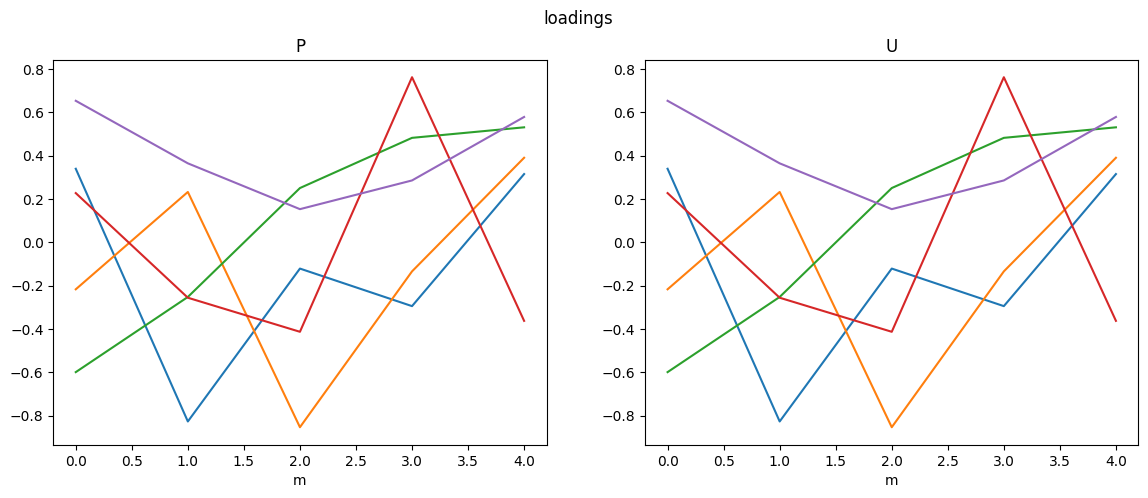

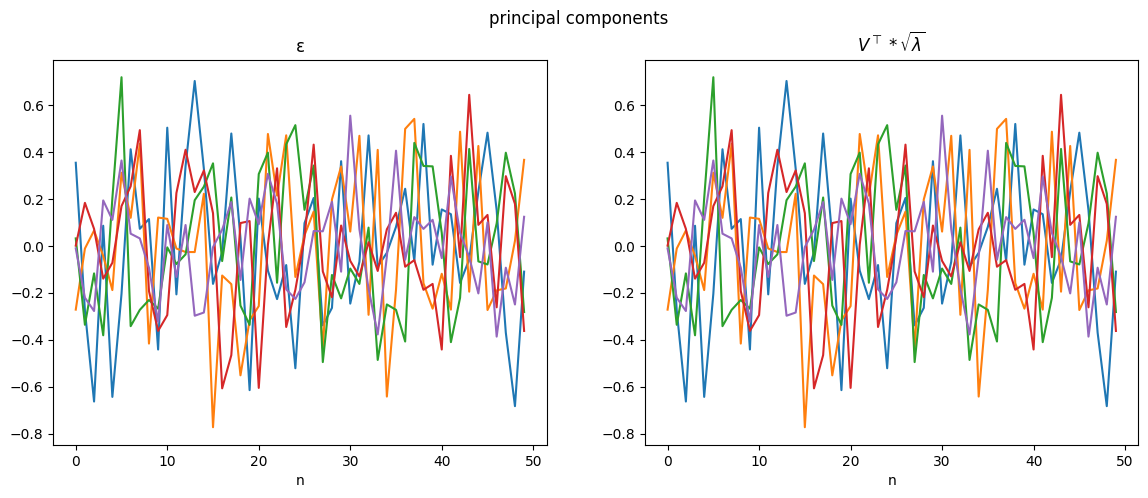

In [19]:
np.set_printoptions(precision=3, suppress=True)
X = np.random.rand(5, 50)
X = X - X.mean(axis=1, keepdims=True)   # нулевые выборочные средние переменных

da = DecomAnalysis(X)
compare_pca_svd(da)

In [20]:
print("λ = σ²:                    ", np.allclose(da.λ, da.σ ** 2))
print("P = U (после выбора знаков):", np.allclose(da.P, da.U))
print("ε = Σ V^T:                 ", np.allclose(da.ε, da.Σ @ da.VT))
print("ε ε^T = Λ (компоненты некоррелированы):", np.allclose(da.ε @ da.ε.T, da.Λ))
print("Накопленная доля дисперсии:", da.explained_ratio_pca.round(3))

for r in range(1, 6):
    da.fit(r)
    err = np.linalg.norm(X - da.X_svd, 'fro')
    print(f"r={r}: PCA == SVD: {np.allclose(da.X_pca, da.X_svd)}, "
          f"||X - X_r||_F = {err:.4f}, sqrt(sum σ_i^2, i>r) = {np.sqrt((da.σ[r:]**2).sum()):.4f}")

λ = σ²:                     True
P = U (после выбора знаков): True
ε = Σ V^T:                  True
ε ε^T = Λ (компоненты некоррелированы): True
Накопленная доля дисперсии: [0.264 0.505 0.719 0.9   1.   ]
r=1: PCA == SVD: True, ||X - X_r||_F = 3.9222, sqrt(sum σ_i^2, i>r) = 3.9222
r=2: PCA == SVD: True, ||X - X_r||_F = 3.2166, sqrt(sum σ_i^2, i>r) = 3.2166
r=3: PCA == SVD: True, ||X - X_r||_F = 2.4225, sqrt(sum σ_i^2, i>r) = 2.4225
r=4: PCA == SVD: True, ||X - X_r||_F = 1.4490, sqrt(sum σ_i^2, i>r) = 1.4490
r=5: PCA == SVD: True, ||X - X_r||_F = 0.0000, sqrt(sum σ_i^2, i>r) = 0.0000


λ = σ², P = U, ε = ΣVᵀ - всё совпадает. Дальше то же на Iris со сверкой со sklearn:

Доля дисперсии (наша):   [0.925 0.053 0.017 0.005]
Доля дисперсии (sklearn): [0.925 0.053 0.017 0.005]
Дисперсии компонент совпадают: True
Нагрузки совпадают с точностью до знака: True


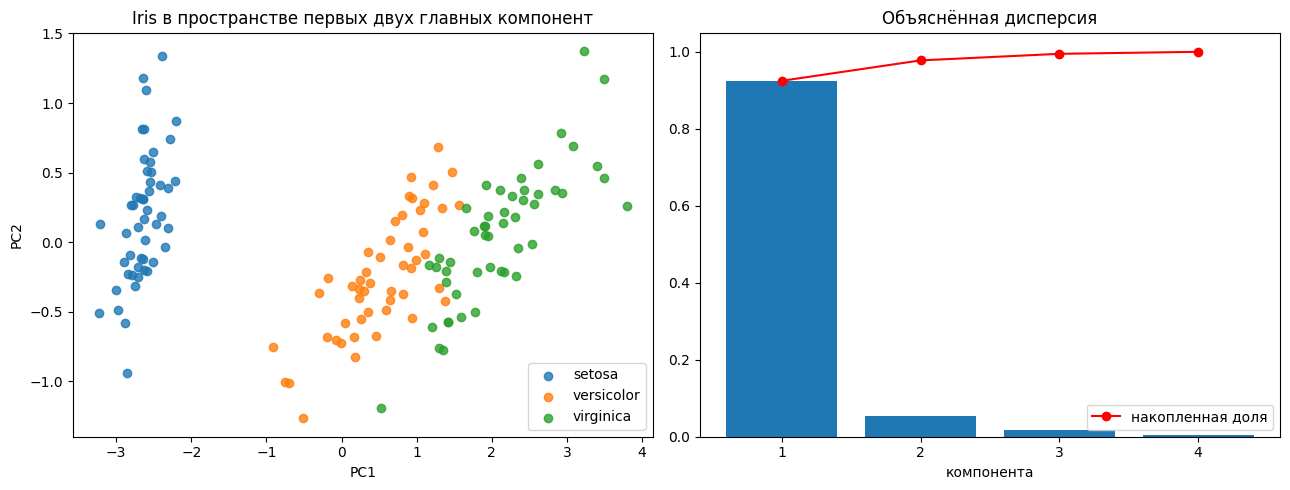

In [21]:
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA

iris = load_iris()
X_iris = iris.data.T                                        # 4 переменные x 150 наблюдений
X_iris = X_iris - X_iris.mean(axis=1, keepdims=True)

da_iris = DecomAnalysis(X_iris)
da_iris.pca(); da_iris.svd()

sk = PCA().fit(iris.data)
print("Доля дисперсии (наша):  ", (da_iris.λ / da_iris.λ.sum()).round(4))
print("Доля дисперсии (sklearn):", sk.explained_variance_ratio_.round(4))
print("Дисперсии компонент совпадают:", np.allclose(da_iris.λ / (X_iris.shape[1] - 1), sk.explained_variance_))
print("Нагрузки совпадают с точностью до знака:",
      np.allclose(np.abs(da_iris.P.T), np.abs(sk.components_)))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for c, name in enumerate(iris.target_names):
    m = iris.target == c
    axes[0].scatter(da_iris.ε[0, m], da_iris.ε[1, m], label=name, alpha=0.8)
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2"); axes[0].legend()
axes[0].set_title("Iris в пространстве первых двух главных компонент")
axes[1].bar(range(1, 5), da_iris.λ / da_iris.λ.sum())
axes[1].plot(range(1, 5), da_iris.explained_ratio_pca, 'ro-', label="накопленная доля")
axes[1].set_xticks(range(1, 5)); axes[1].set_xlabel("компонента"); axes[1].legend()
axes[1].set_title("Объяснённая дисперсия")
plt.tight_layout(); plt.show()

Совпадает со sklearn: PC1 ≈ 92.5 %, PC1 + PC2 ≈ 97.8 %.

## Exercises

## Упражнение

В методе обычных наименьших квадратов (OLS) мы учимся вычислять $ \hat{\beta} = (X^\top X)^{-1} X^\top y $, но бывают случаи, например, когда у нас есть коллинеарность или недоопределенная система: **короткая толстая** матрица.

В этих случаях матрица $(X^\top X)$ не является необратимой (ее определитель равен нулю) или плохо обусловленной (ее определитель очень близок к нулю).

Вместо этого мы можем создать так называемую [псевдообратную](https://en.wikipedia.org/wiki/Moore%E2%80%93Penrose_inverse), аппроксимацию инвертированной матрицы полного ранга, чтобы мы могли вычислить с ее помощью $ \hat{\beta} $.

Думая в терминах теоремы Эккарта-Янга, постройте псевдообратную матрицу $ X^{+} $ и используйте ее для вычисления $ \hat{\beta} $.

**Решение.** X⁺ = V Σ⁺ Uᵀ: малые σ обнуляю по порогу, параметр r - усечение по Эккарту–Янгу.
Проверяю 3 случая: полный ранг, коллинеарность, недоопределённая система.

In [22]:
def pseudo_inverse(X, r=None, tol=None):
    """Псевдообратная Мура–Пенроуза через SVD; r — число оставляемых сингулярных чисел."""
    U, s, VT = np.linalg.svd(X, full_matrices=False)
    if tol is None:
        tol = max(X.shape) * np.finfo(float).eps * s[0]   # как в np.linalg.pinv / matrix_rank
    keep = s > tol
    if r is not None:
        keep[r:] = False
    s_inv = np.zeros_like(s)
    s_inv[keep] = 1.0 / s[keep]
    return VT.T @ np.diag(s_inv) @ U.T

rng = np.random.default_rng(1)

# 1) Обычная переопределённая задача (высокая худая матрица полного ранга)
X1 = rng.normal(size=(100, 3))
beta_true = np.array([2.0, -1.0, 0.5])
y1 = X1 @ beta_true + 0.1 * rng.normal(size=100)
b_ols = np.linalg.inv(X1.T @ X1) @ X1.T @ y1
b_pinv = pseudo_inverse(X1) @ y1
print("1) Полный ранг:    beta_OLS =", b_ols.round(4), "| beta_pinv =", b_pinv.round(4),
      "| совпадают:", np.allclose(b_ols, b_pinv))

# 2) Точная коллинеарность: x3 = x1 + x2 -> X^T X вырождена
X2 = np.column_stack([X1[:, 0], X1[:, 1], X1[:, 0] + X1[:, 1]])
y2 = X1[:, :2] @ np.array([1.0, 2.0]) + 0.1 * rng.normal(size=100)
print(f"\n2) Коллинеарность: cond(X^T X) = {np.linalg.cond(X2.T @ X2):.2e}, "
      f"det(X^T X) = {np.linalg.det(X2.T @ X2):.2e}")
try:
    b_bad = np.linalg.inv(X2.T @ X2) @ X2.T @ y2
    print("   inv(X^T X) формально вычислилась, но beta =", b_bad.round(2), "— численный мусор")
except np.linalg.LinAlgError as e:
    print("   inv(X^T X) не существует:", e)
b2 = pseudo_inverse(X2) @ y2
print("   beta_pinv =", b2.round(4))
print("   совпадает с np.linalg.pinv:", np.allclose(b2, np.linalg.pinv(X2) @ y2),
      "| с lstsq:", np.allclose(b2, np.linalg.lstsq(X2, y2, rcond=None)[0]))
# Любое решение МНК имеет вид b2 + t * (1, 1, -1); у псевдообратного норма минимальна
null_dir = np.array([1, 1, -1]) / np.sqrt(3)
for t in [0, 0.5, 2]:
    b = b2 + t * null_dir
    print(f"   t={t}: ||y - Xb|| = {np.linalg.norm(y2 - X2 @ b):.4f}, ||b|| = {np.linalg.norm(b):.4f}")

1) Полный ранг:    beta_OLS = [ 2.001 -0.992  0.499] | beta_pinv = [ 2.001 -0.992  0.499] | совпадают: True

2) Коллинеарность: cond(X^T X) = 4.94e+16, det(X^T X) = 1.18e-10
   inv(X^T X) формально вычислилась, но beta = [-1.98  0.32  2.29] — численный мусор
   beta_pinv = [-0.004  1.003  0.999]
   совпадает с np.linalg.pinv: True | с lstsq: True
   t=0: ||y - Xb|| = 0.9112, ||b|| = 1.4155
   t=0.5: ||y - Xb|| = 0.9112, ||b|| = 1.5012
   t=2: ||y - Xb|| = 0.9112, ||b|| = 2.4502


In [23]:
# 3) Недоопределённая система: 5 уравнений, 10 неизвестных (короткая толстая матрица)
X3 = rng.normal(size=(5, 10))
y3 = rng.normal(size=5)
b3 = pseudo_inverse(X3) @ y3
print("3) Недоопределённая: X b = y точно:", np.allclose(X3 @ b3, y3), "| ||b|| =", round(np.linalg.norm(b3), 4))
N = np.linalg.svd(X3)[2][5:].T                 # базис нуль-пространства X3 (5-мерный)
b_other = b3 + N @ rng.normal(size=5)          # другое точное решение
print("   другое решение тоже точное:", np.allclose(X3 @ b_other, y3),
      "| но его норма больше:", round(np.linalg.norm(b_other), 4))
print("   b_pinv ⟂ N(X) (лежит в пространстве строк):", np.allclose(N.T @ b3, 0))

3) Недоопределённая: X b = y точно: True | ||b|| = 0.7056
   другое решение тоже точное: True | но его норма больше: 1.725
   b_pinv ⟂ N(X) (лежит в пространстве строк): True


Усечённая псевдообратная на плохо обусловленной задаче:

In [24]:
n_train, n_test = 40, 1000
Z = rng.normal(size=(n_train + n_test, 4))
Xc = np.hstack([Z, Z + 1e-3 * rng.normal(size=Z.shape)])     # 8 признаков, ранг «почти» 4
beta_c = np.array([1, 2, -1, 0.5, 1, 2, -1, 0.5])
yc = Xc @ beta_c + 0.5 * rng.normal(size=n_train + n_test)
Xtr, ytr, Xte, yte = Xc[:n_train], yc[:n_train], Xc[n_train:], yc[n_train:]

s_c = np.linalg.svd(Xtr, compute_uv=False)
print("Сингулярные числа обучающей матрицы:", s_c.round(4))
print(f"Число обусловленности: {s_c[0] / s_c[-1]:.1e}\n")
for r in range(1, 9):
    b = pseudo_inverse(Xtr, r=r) @ ytr
    mse = np.mean((Xte @ b - yte) ** 2)
    print(f"r={r}: ||beta|| = {np.linalg.norm(b):9.2f}, MSE на тесте = {mse:8.3f}")

Сингулярные числа обучающей матрицы: [11.377 10.871  9.659  8.921  0.005  0.004  0.003  0.003]
Число обусловленности: 3.6e+03

r=1: ||beta|| =      0.13, MSE на тесте =   25.106
r=2: ||beta|| =      1.27, MSE на тесте =   20.653
r=3: ||beta|| =      3.50, MSE на тесте =    0.438
r=4: ||beta|| =      3.51, MSE на тесте =    0.265
r=5: ||beta|| =     39.36, MSE на тесте =    0.265
r=6: ||beta|| =    147.44, MSE на тесте =    0.283
r=7: ||beta|| =    150.04, MSE на тесте =    0.285
r=8: ||beta|| =    226.18, MSE на тесте =    0.311


- Полный ранг: совпадает с МНК.
- Коллинеарность: `inv(XᵀX)` даёт мусор, псевдообратная - решение минимальной нормы.
- Недоопределённая система: точное решение минимальной нормы.
- Усечение до r = 4 стабилизирует коэффициенты: ‖β‖ ≈ 3.5 против 226 при r = 8.

## Выводы
SVD даёт базисы 4 подпространств, лучшее низкоранговое приближение, полярное разложение, PCA и псевдообратную; всё проверено численно.